--- Weighted Prevalence ---
       cycle  weighted_prevalence_pct
0  2005-2006                 2.882182
1  2007-2008                 3.389975
2  2009-2010                 3.192709
3  2011-2012                 3.238998
4  2013-2014                 3.346928
5  2015-2016                 3.354723
6  2017-2018                 3.402176


   sex  weighted_prevalence_pct
0    1                 3.083699
1    2                 3.436460


  age_group  weighted_prevalence_pct
0  (18, 29]                 3.294118
1  (29, 44]                 3.175808
2  (44, 59]                 3.656523
3  (59, 80]                 2.893584


   ethnicity  weighted_prevalence_pct
0          1                 3.770827
1          2                 6.147862
2          3                 2.934463
3          4                 3.472515
4          5                 3.236611


--- Univariate Risk Ratios ---
              Feature  Risk Ratio
  mental_health_visit        3.92
        sleep_trouble        2.79
        hospital_s

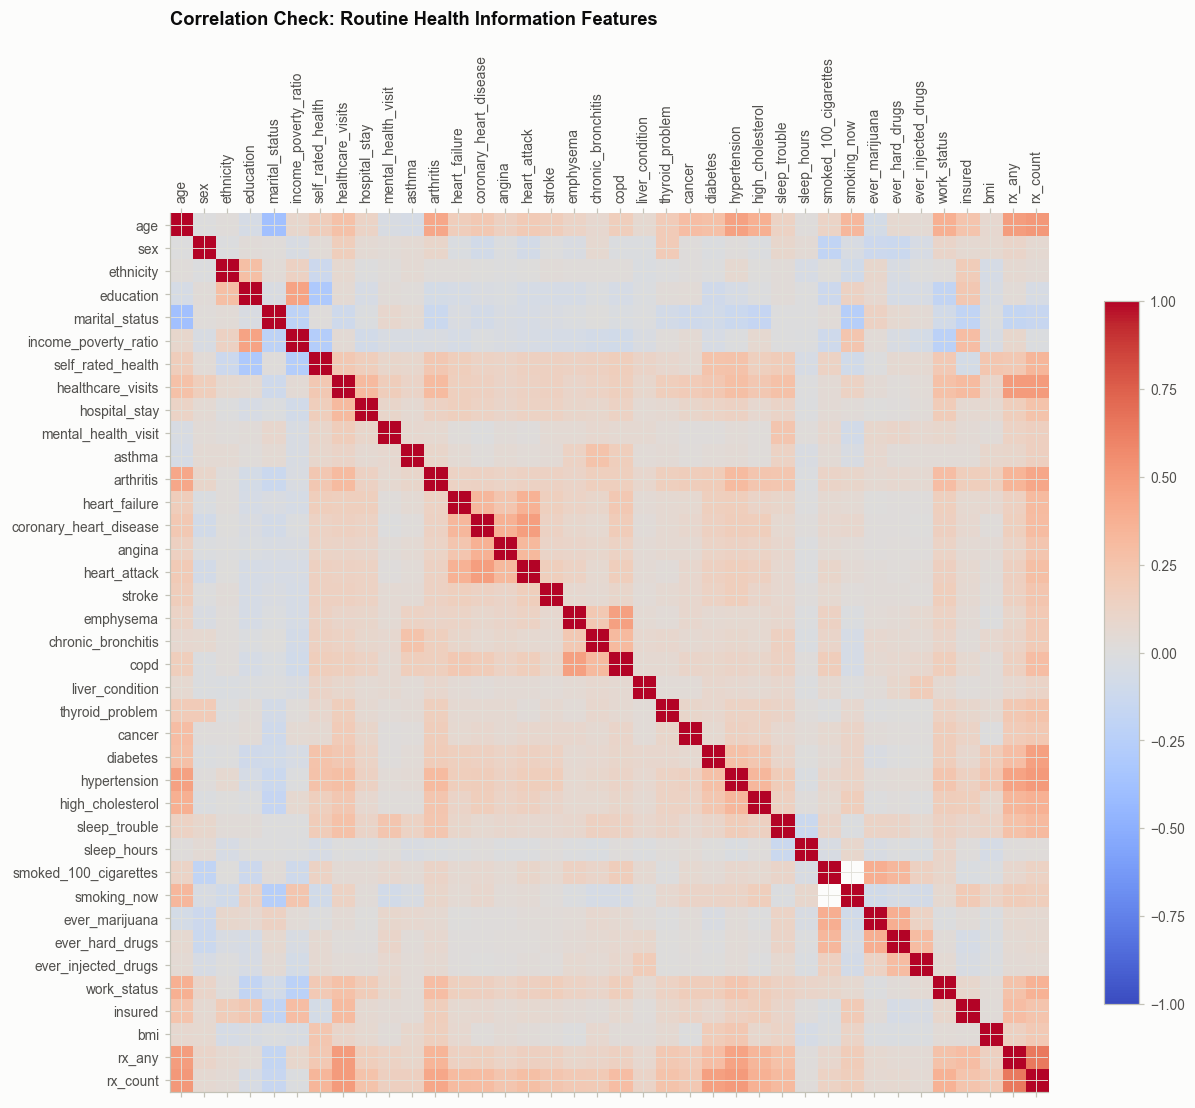

--- Highly Collinear Feature Pairs (|r| > 0.5) ---
Feature 1 Feature 2  Correlation
   rx_any  rx_count     0.640863
      age  rx_count     0.500885


In [1]:
## STEP-03 exploratory analysis 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from hidden_risk.config import DATA_PROCESSED
from hidden_risk.plotting import use_style

# Apply the team's shared plotting style
use_style()

# 1. Load the processed dataset
df = pd.read_parquet(DATA_PROCESSED / "nhanes_2005_2018.parquet")

# ---------------------------------------------------------
# ---------------------------------------------------------
# TASK 1: Weighted Prevalence by Subgroups
# ---------------------------------------------------------
def weighted_prevalence(df, group_col, weight_col="weight_mec_pooled", outcome="si"):
    """Calculates the weighted prevalence of suicidal ideation for a given group."""
    def wavg(group):
        # Weighted mean: sum(value * weight) / sum(weight)
        return np.average(group[outcome], weights=group[weight_col])
    
    prev = df.dropna(subset=[group_col, outcome, weight_col])
    # Added observed=True and include_groups=False to silence pandas FutureWarnings
    result = prev.groupby(group_col, observed=True).apply(wavg, include_groups=False) * 100
    return result.reset_index(name="weighted_prevalence_pct")

print("--- Weighted Prevalence ---")
# Bin age into groups for a cleaner summary
df['age_group'] = pd.cut(df['age'], bins=[18, 29, 44, 59, 80], right=True)

for demographic in ["cycle", "sex", "age_group", "ethnicity"]:
    print(weighted_prevalence(df, demographic))
    print("\n")
# ---------------------------------------------------------
# TASK 2: Univariate Risk Ratios
# ---------------------------------------------------------
def calculate_risk_ratio(df, feature, outcome="si"):
    """Calculates the crude risk ratio of a binary feature against the outcome."""
    valid_data = df[[feature, outcome]].dropna()
    
    # Risk if feature is present
    risk_exposed = valid_data[valid_data[feature] == 1][outcome].mean()
    # Risk if feature is absent
    risk_unexposed = valid_data[valid_data[feature] == 0][outcome].mean()
    
    if risk_unexposed == 0:
        return np.nan
    return risk_exposed / risk_unexposed

# Routine health features from Step 1/2
features = [
    "sleep_trouble", "hospital_stay", "mental_health_visit", "asthma", 
    "arthritis", "diabetes", "hypertension", "smoked_100_cigarettes", 
    "ever_marijuana", "ever_hard_drugs"
]

print("--- Univariate Risk Ratios ---")
rr_results = []
for f in features:
    if f in df.columns:
        rr = calculate_risk_ratio(df, f)
        rr_results.append({"Feature": f, "Risk Ratio": round(rr, 2)})

rr_df = pd.DataFrame(rr_results).sort_values(by="Risk Ratio", ascending=False)
print(rr_df.to_string(index=False))
print("\n")

# ---------------------------------------------------------
# TASK 3: Collinearity Check (Correlation Matrix)
# ---------------------------------------------------------
# Exclude demographic, survey design, and outcome/leakage columns
exclude_cols = [
    'seqn', 'cycle', 'split', 'weight_mec_pooled', 'strata', 'psu', 
    'weight_mec', 'weight_interview', 'age_group', 'si', 'si_strict'
] 
exclude_cols += [col for col in df.columns if 'phq' in col]

corr_features = [c for c in df.columns if c not in exclude_cols and pd.api.types.is_numeric_dtype(df[c])]

# Calculate Pearson correlation matrix
corr_matrix = df[corr_features].corr()

# Plot the heatmap using matplotlib
fig, ax = plt.subplots(figsize=(12, 10))
cax = ax.matshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(cax, shrink=0.8)

# Set ticks and format labels
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.columns)))
ax.set_xticklabels(corr_matrix.columns, rotation=90)
ax.set_yticklabels(corr_matrix.columns)
plt.title("Correlation Check: Routine Health Information Features", pad=20)
plt.tight_layout()
plt.show()

# Print highly correlated pairs (|r| > 0.5)
print("--- Highly Collinear Feature Pairs (|r| > 0.5) ---")
high_corr = corr_matrix.unstack().reset_index()
high_corr.columns = ['Feature 1', 'Feature 2', 'Correlation']
high_corr = high_corr[
    (high_corr['Feature 1'] != high_corr['Feature 2']) & 
    (high_corr['Correlation'].abs() > 0.5)
].drop_duplicates(subset=['Correlation']).sort_values(by='Correlation', ascending=False)

print(high_corr.to_string(index=False))